<a href="https://colab.research.google.com/github/huiyzhao/MSSP607/blob/main/WeeklyModules/Week08/huiyzhao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import os
import subprocess

owner = "huiyzhao"
repository = "MSSP607"

repo_url = f"https://github.com/huiyzhao/MSSP607.git"

if not os.path.exists (repository):
  subprocess.run(["git", "clone", repo_url], check=True)

os.chdir(repository)
print("Current folder:", os.getcwd())

Current folder: /content/MSSP607/MSSP607


In [14]:
import pandas as pd
subprocess.run(["git", "pull"], check=True)
file_path = "WeeklyModules/Week08/InternetSales.csv"
sales = pd.read_csv(file_path, encoding="latin1")

print("Rows and Columns:", sales.shape)
print("\nColumn names:")
print(sales.columns.tolist())

sales.head()

/tmp/ipykernel_835/215877690.py:4: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv(file_path, encoding="latin1")


Rows and Columns: (60398, 60)

Column names:
['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode', 'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title', 'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate', 'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation', 'SpanishEducation', 'FrenchEducation', 'EnglishOccupation', 'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone', 'DateFirstPurchase', 'CommuteDistance', 'ProductKey', 'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey', 'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber', 'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct', 'DiscountAmount', 'ProductStandardCost', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'Freight', 'CarrierTrackingNumber', 'Custom

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [15]:
sales.columns

Index(['ID', 'CustomerKey', 'GeographyKey', 'City', 'CountryRegionCode',
       'EnglishCountryRegionName', 'CustomerAlternateKey', 'Title',
       'FirstName', 'MiddleName', 'LastName', 'NameStyle', 'BirthDate',
       'MaritalStatus', 'Suffix', 'Gender', 'EmailAddress', 'YearlyIncome',
       'TotalChildren', 'NumberChildrenAtHome', 'EnglishEducation',
       'SpanishEducation', 'FrenchEducation', 'EnglishOccupation',
       'SpanishOccupation', 'FrenchOccupation', 'HouseOwnerFlag',
       'NumberCarsOwned', 'AddressLine1', 'AddressLine2', 'Phone',
       'DateFirstPurchase', 'CommuteDistance', 'ProductKey',
       'EnglishProductName', 'OrderDateKey', 'DueDateKey', 'ShipDateKey',
       'CustomerKey.1', 'PromotionKey', 'CurrencyKey', 'SalesTerritoryKey',
       'SalesOrderNumber', 'SalesOrderLineNumber', 'RevisionNumber',
       'OrderQuantity', 'UnitPrice', 'ExtendedAmount', 'UnitPriceDiscountPct',
       'DiscountAmount', 'ProductStandardCost', 'TotalProductCost',
       'SalesAmo

In [16]:
product_sales = sales.groupby("EnglishProductName")["SalesAmount"].sum()
product_sales.sort_values(ascending=False).head()

,SalesAmount
EnglishProductName,
"Mountain-200 Black, 46",1.373470e+06
"Mountain-200 Black, 42",1.363142e+06
"Mountain-200 Silver, 38",1.339463e+06
"Mountain-200 Silver, 46",1.301100e+06
"Mountain-200 Black, 38",1.294866e+06


In [17]:
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
yearly_sales = sales.groupby(sales["OrderDate"].dt.year)["SalesAmount"].sum()
yearly_sales

,SalesAmount
OrderDate,
2010,4.342104e+04
2011,7.075526e+06
2012,5.842485e+06
2013,1.635155e+07
2014,4.569472e+04


In [18]:
sales.groupby(sales["OrderDate"].dt.year)["OrderDate"].agg(["min","max","count"])

,min,max,count
OrderDate,,,
2010,2010-12-29,2010-12-31,14
2011,2011-01-01,2011-12-31,2216
2012,2012-01-01,2012-12-31,3397
2013,2013-01-01,2013-12-31,52801
2014,2014-01-01,2014-01-28,1970


In [19]:
full_sales = sales[
    (sales["OrderDate"]>="2011-01-01")&
    (sales["OrderDate"]<="2013-12-31")
].copy()

monthly_sales = full_sales.set_index("OrderDate")["SalesAmount"].resample("MS").sum()
monthly_sales.head()

,SalesAmount
OrderDate,
2011-01-01,469823.9148
2011-02-01,466334.9030
2011-03-01,485198.6594
2011-04-01,502073.8458
2011-05-01,561681.4758


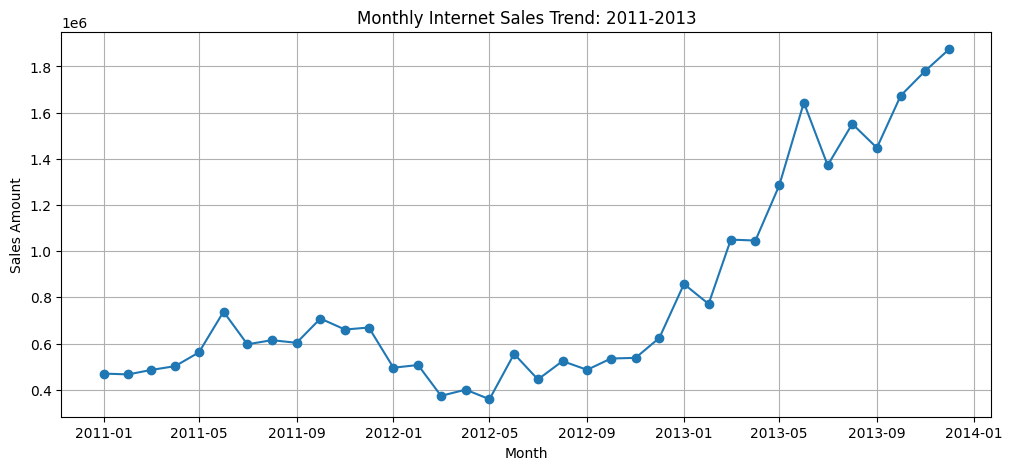

In [20]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Internet Sales Trend: 2011-2013")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.grid(True)
plt.show()

In [26]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

model = ExponentialSmoothing(
    monthly_sales,
    trend="add",
    seasonal="add",
    seasonal_periods=12
)

fit = model.fit()

forecast_60m = fit.forecast(60)
forecast_60m.head()

,0
2014-01-01,1.949116e+06
2014-02-01,1.996462e+06
2014-03-01,2.142314e+06
2014-04-01,2.235284e+06
2014-05-01,2.396946e+06


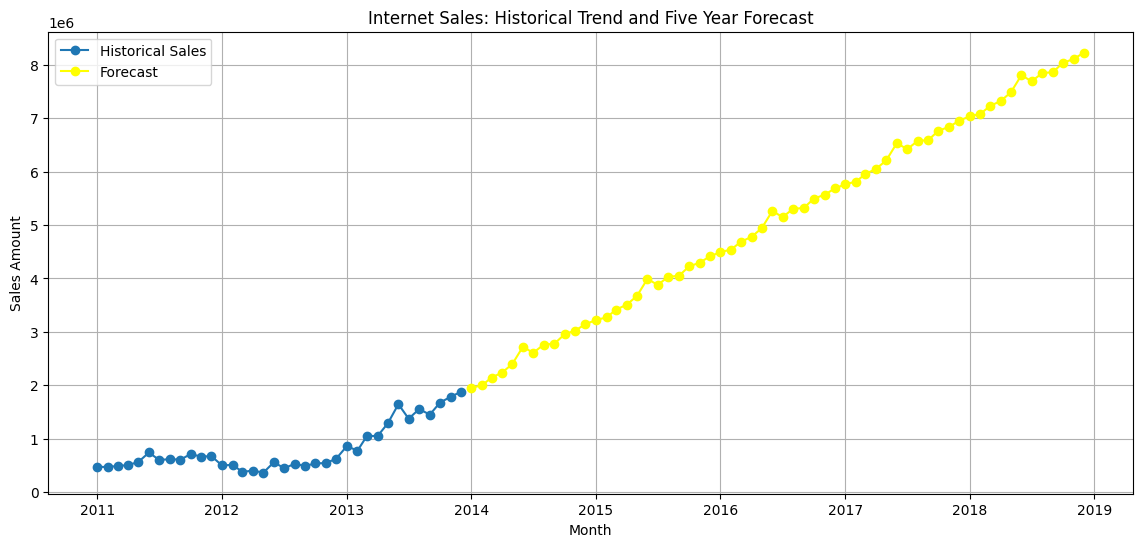

In [28]:
plt.figure(figsize=(14,6))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    label="Historical Sales",
    marker="o"
)

plt.plot(
    forecast_60m.index,
    forecast_60m.values,
    label="Forecast",
    color="yellow",
    marker="o"
)

plt.title("Internet Sales: Historical Trend and Five Year Forecast")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.grid(True)
plt.legend()

plt.show()